# 05 · Training Better Models: Optimizers, Losses, Activations, Metrics
**Course Module 5: Optimization, loss functions and metrics, activation functions**

**Strategy:** notebooks 03–04 fixed the *model* and the *data*. Now we study *how* the model learns, and how we *measure* it, again with controlled experiments (one change per run).
Then we tackle the most dangerous problem from notebook 02: the model is **confidently wrong** in the field. For a farmer, a wrong answer stated with 90% confidence is worse than "I'm not sure".

| Part | Question |
|---|---|
| A. Optimizers | SGD with momentum or AdamW? |
| B. Loss functions | Cross-entropy, label smoothing or focal loss? |
| C. Activations | ReLU, SiLU or GELU in our scratch CNN? |
| D. Metrics | Why accuracy is not enough: macro-F1, confusion matrix, per-class F1 |
| E. Calibration | Make the confidence honest (temperature scaling, ECE, reliability diagram) |
| F. Abstention | Let the app say "not sure", and measure the accuracy of the answers it does give |
| G. Final model | Train the best combination for the app |

In [1]:
import json, torch, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from lab_to_field.config import CLASSES, N_CLASSES, FIGURES_DIR, RESULTS_DIR, CHECKPOINT_DIR
from lab_to_field.train import TrainConfig, load_results, predict
from lab_to_field.experiment import run, splits
from lab_to_field.metrics import summarize, confusion, reliability_curve, expected_calibration_error
from lab_to_field.calibrate import fit_temperature, softmax, risk_coverage
plt.rcParams["figure.dpi"] = 110
R = load_results()
aug_runs = {k: v for k, v in R.items() if k.startswith("04_aug_") or k == "03_mnv3_finetune"}
# Choices are always made on field VALIDATION; the field test set is only reported.
best_run = max(aug_runs, key=lambda k: aug_runs[k]["field_val"]["accuracy"])
BEST_AUG = aug_runs[best_run]["config"]["augment"]
print("best augmentation from notebook 04 (chosen on field validation):", BEST_AUG,
      f"-> {aug_runs[best_run]['field_val']['accuracy']:.1%} field val accuracy")

best augmentation from notebook 04 (chosen on field validation): bg_field -> 28.9% field val accuracy


## A. Optimizers

| Optimizer | Update rule, in words | Typical behaviour |
|---|---|---|
| **SGD + momentum** | step against the gradient; momentum keeps a running average of past steps (like a rolling ball) | needs a well-tuned learning rate; often generalises well |
| **Adam** | per-parameter step sizes from running averages of the gradient (1st moment) and its square (2nd moment) | fast and forgiving of the learning rate |
| **AdamW** | Adam + weight decay applied *directly* to the weights instead of through the gradient | the modern default for fine-tuning |

Both use the same schedule: warm-up for 5% of steps, then **cosine decay**. Warm-up avoids big destructive steps while the new head is still random; decay lets the model settle into a minimum.

In [2]:
base = dict(model="mobilenetv3_large_100", epochs=6, augment=BEST_AUG)
run(TrainConfig(name="05_opt_adamw", optimizer="adamw", lr=1e-3, **base))
run(TrainConfig(name="05_opt_sgd", optimizer="sgd", lr=1e-2, **base))   # SGD needs a ~10x larger lr

[05_opt_adamw] loaded saved result (delete 05_opt_adamw.json or pass force=True to retrain): lab acc 0.983 | field val 0.289 | field test 0.314
[05_opt_sgd] loaded saved result (delete 05_opt_sgd.json or pass force=True to retrain): lab acc 0.969 | field val 0.277 | field test 0.335


{'config': {'name': '05_opt_sgd',
  'model': 'mobilenetv3_large_100',
  'epochs': 6,
  'lr': 0.01,
  'weight_decay': 0.0001,
  'optimizer': 'sgd',
  'loss': 'ce',
  'batch_size': 64,
  'img_size': 224,
  'augment': 'bg_field',
  'freeze_backbone': False,
  'act': 'relu',
  'seed': 0,
  'extra': {}},
 'history': [{'epoch': 1,
   'train_loss': 1.1540517820976675,
   'val_acc': 0.9250325945241199},
  {'epoch': 2,
   'train_loss': 0.2509822009014897,
   'val_acc': 0.9419817470664928},
  {'epoch': 3,
   'train_loss': 0.18461247175582685,
   'val_acc': 0.9478487614080835},
  {'epoch': 4,
   'train_loss': 0.13631577200915976,
   'val_acc': 0.954367666232073},
  {'epoch': 5,
   'train_loss': 0.10868741332281691,
   'val_acc': 0.9621903520208605},
  {'epoch': 6,
   'train_loss': 0.09692545061504158,
   'val_acc': 0.9608865710560626}],
 'best_val_acc': 0.9621903520208605,
 'train_minutes': 3.5966264168421427,
 'track': 'lab',
 'params_total': 4237900,
 'params_trainable': 4237900,
 'n_train': 12

## B. Loss functions

| Loss | Formula idea | Why try it |
|---|---|---|
| **Cross-entropy (CE)** | −log p(correct class) | the standard for classification |
| **Label smoothing (0.1)** | target is 0.9 for the true class and 0.1 spread over the others | stops the model pushing its confidence to 100%, which often improves calibration |
| **Focal loss (γ = 2)** | CE × (1 − p)^γ | down-weights easy images, focuses on hard ones (helps with class imbalance) |

In [3]:
R = load_results()
best_opt = "adamw" if R["05_opt_adamw"]["field_val"]["accuracy"] >= R["05_opt_sgd"]["field_val"]["accuracy"] else "sgd"
lr = 1e-3 if best_opt == "adamw" else 1e-2
print("best optimizer (on field validation):", best_opt)
for loss in ["label_smoothing", "focal"]:
    run(TrainConfig(name=f"05_loss_{loss}", optimizer=best_opt, lr=lr, loss=loss, **base))

best optimizer (on field validation): adamw
[05_loss_label_smoothing] loaded saved result (delete 05_loss_label_smoothing.json or pass force=True to retrain): lab acc 0.983 | field val 0.294 | field test 0.364
[05_loss_focal] loaded saved result (delete 05_loss_focal.json or pass force=True to retrain): lab acc 0.980 | field val 0.243 | field test 0.297


## C. Activation functions
Tested in the **scratch CNN** from notebook 02, where we control every layer (the pretrained models come with their activations fixed).

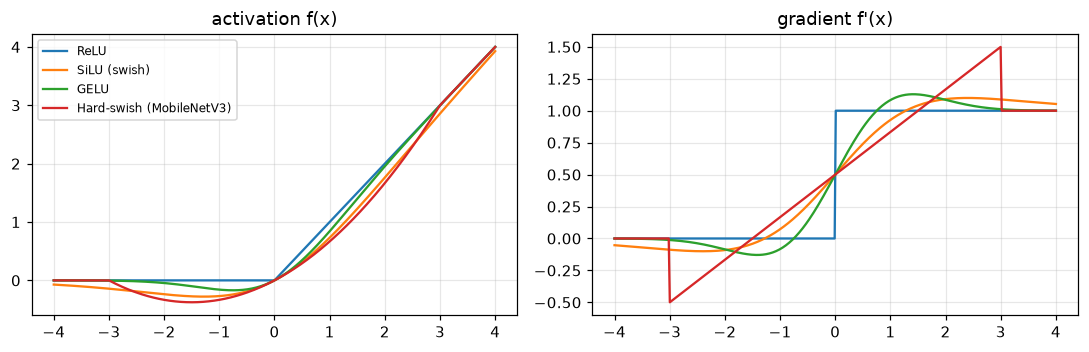

In [4]:
xs = torch.linspace(-4, 4, 400)
acts = {"ReLU": torch.relu, "SiLU (swish)": torch.nn.functional.silu, "GELU": torch.nn.functional.gelu,
        "Hard-swish (MobileNetV3)": torch.nn.functional.hardswish}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.3))
for name, f in acts.items():
    x = xs.clone().requires_grad_(True); y = f(x); y.sum().backward()
    a1.plot(xs, y.detach(), label=name); a2.plot(xs, x.grad, label=name)
a1.set_title("activation f(x)"); a2.set_title("gradient f'(x)"); a1.legend(fontsize=8); a1.grid(alpha=.3); a2.grid(alpha=.3)
plt.tight_layout(); fig.savefig(FIGURES_DIR / "05_activations.png", bbox_inches="tight")

**Read the plot:** ReLU's gradient is exactly 0 for negative inputs, so a neuron that only gets negative inputs stops learning ("dying ReLU").
SiLU and GELU are smooth and let a small negative signal through. Hard-swish is a cheap piecewise approximation of SiLU, made for phones.

In [5]:
for act in ["silu", "gelu"]:
    run(TrainConfig(name=f"05_act_{act}", model="simple_cnn", act=act, epochs=12, lr=3e-3, augment="basic"))

[05_act_silu] loaded saved result (delete 05_act_silu.json or pass force=True to retrain): lab acc 0.954 | field val 0.094 | field test 0.102
[05_act_gelu] loaded saved result (delete 05_act_gelu.json or pass force=True to retrain): lab acc 0.960 | field val 0.080 | field test 0.102


In [6]:
R = load_results()
def row(n, label):
    r = R[n]; return {"experiment": label, "lab acc": r["lab_test"]["accuracy"], "field val acc": r["field_val"]["accuracy"],
                      "field acc": r["field_test"]["accuracy"],
                      "field macro-F1": r["field_test"]["macro_f1"], "field ECE": r["field_test"]["ece"],
                      "field mean confidence": r["field_test"]["mean_confidence"]}
summary_tbl = pd.DataFrame([
    row("05_opt_adamw", "A · AdamW (CE)"), row("05_opt_sgd", "A · SGD momentum (CE)"),
    row(f"05_loss_label_smoothing", f"B · {best_opt} + label smoothing"), row("05_loss_focal", f"B · {best_opt} + focal"),
    row("02_simple_cnn", "C · scratch CNN, ReLU"), row("05_act_silu", "C · scratch CNN, SiLU"), row("05_act_gelu", "C · scratch CNN, GELU"),
])
summary_tbl.round(3)

,experiment,lab acc,field val acc,field acc,field macro-F1,field ECE,field mean confidence
0,A · AdamW (CE),0.983,0.289,0.314,0.287,0.444,0.758
1,A · SGD momentum (CE),0.969,0.277,0.335,0.304,0.369,0.701
2,B · adamw + label smoothing,0.983,0.294,0.364,0.320,0.157,0.517
3,B · adamw + focal,0.980,0.243,0.297,0.262,0.370,0.667
4,"C · scratch CNN, ReLU",0.958,0.071,0.089,0.079,0.690,0.777
5,"C · scratch CNN, SiLU",0.954,0.094,0.102,0.088,0.662,0.763
6,"C · scratch CNN, GELU",0.960,0.080,0.102,0.088,0.673,0.771


**What to look for:**
- **field val acc** decides which optimizer and loss we keep (field acc is only reported).
- **field ECE** and **mean confidence vs accuracy** show *honesty*. Label smoothing often lowers ECE even when accuracy is similar.
- Activation differences in a small CNN are usually small. That is a valid finding too: the data problem (notebook 04) matters far more than the activation.

## D. Metrics: why accuracy is not enough
Next we load the best MobileNetV3 run's saved field predictions.

best Module 5 configuration: 05_loss_label_smoothing {'optimizer': 'adamw', 'loss': 'label_smoothing', 'augment': 'bg_field'}


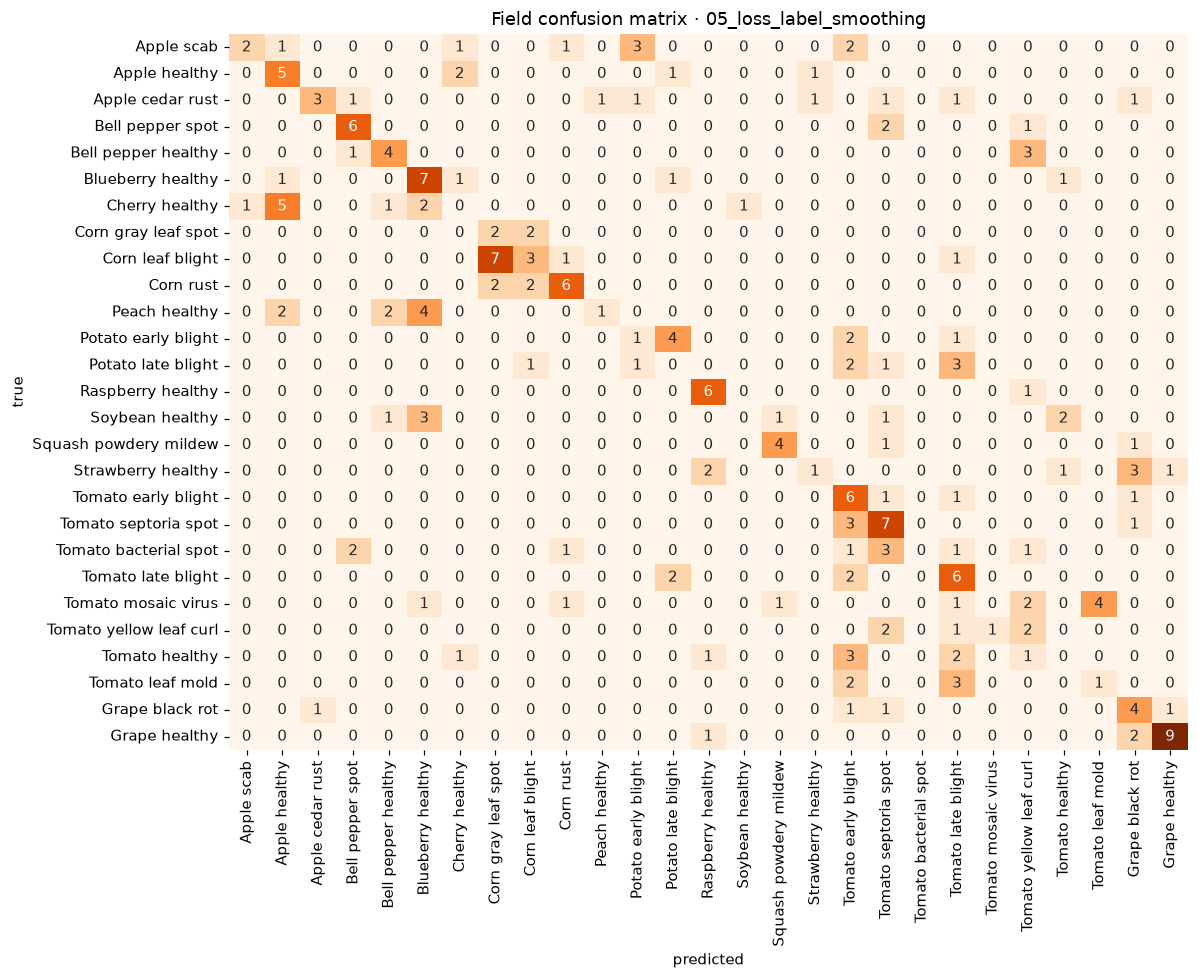

In [7]:
cands = ["05_opt_adamw", "05_opt_sgd", "05_loss_label_smoothing", "05_loss_focal"]
best_name = max(cands, key=lambda n: R[n]["field_val"]["accuracy"])
best_cfg = R[best_name]["config"]
print("best Module 5 configuration:", best_name, {k: best_cfg[k] for k in ("optimizer", "loss", "augment")})
d = np.load(RESULTS_DIR / "preds" / f"{best_name}__field_test.npz")
logits, labels = d["logits"], d["labels"]; probs = softmax(logits)
cm = confusion(probs, labels, N_CLASSES)
present = sorted(set(labels))
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cm[np.ix_(present, present)], annot=True, fmt="d", cbar=False, cmap="Oranges",
            xticklabels=[CLASSES[i] for i in present], yticklabels=[CLASSES[i] for i in present], ax=ax)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Field confusion matrix · {best_name}")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "05_confusion_field.png", bbox_inches="tight")

In [8]:
from sklearn.metrics import precision_recall_fscore_support
p, r, f, s = precision_recall_fscore_support(labels, probs.argmax(1), labels=present, zero_division=0)
per_class = pd.DataFrame({"class": [CLASSES[i] for i in present], "precision": p, "recall": r, "F1": f, "test images": s}).sort_values("F1")
off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:6], off.shape))[0]
print("most common field confusions (true → predicted):")
for t, pr in top: print(f"  {CLASSES[t]:<24} → {CLASSES[pr]:<24} {off[t, pr]} images")
per_class.round(2)

most common field confusions (true → predicted):
  Corn leaf blight         → Corn gray leaf spot      7 images
  Cherry healthy           → Apple healthy            5 images
  Tomato mosaic virus      → Tomato leaf mold         4 images
  Potato early blight      → Potato late blight       4 images
  Peach healthy            → Blueberry healthy        4 images
  Strawberry healthy       → Grape black rot          3 images


,class,precision,recall,F1,test images
6,Cherry healthy,0.00,0.00,0.00,10
14,Soybean healthy,0.00,0.00,0.00,8
12,Potato late blight,0.00,0.00,0.00,8
19,Tomato bacterial spot,0.00,0.00,0.00,9
21,Tomato mosaic virus,0.00,0.00,0.00,10
23,Tomato healthy,0.00,0.00,0.00,8
11,Potato early blight,0.17,0.12,0.14,8
10,Peach healthy,0.50,0.11,0.18,9
16,Strawberry healthy,0.33,0.12,0.18,8
24,Tomato leaf mold,0.20,0.17,0.18,6


| Metric | What it answers | Why we need it here |
|---|---|---|
| Accuracy | % of all photos right | dominated by big classes |
| **Precision** (per class) | when the model says "late blight", how often is it right? | a false alarm means unnecessary spraying |
| **Recall** (per class) | of all real late-blight photos, how many did it find? | a miss means the disease spreads |
| **F1** | harmonic mean of precision and recall | one number per class |
| **Macro-F1** | average F1 over classes | every disease counts equally, however rare |
| **Confusion matrix** | which classes get mixed up | shows *what* to fix (e.g. tomato early vs late blight look alike) |

## E. Calibration: make the confidence honest
**ECE (expected calibration error):** group predictions by confidence (e.g. all predictions made with 70–80% confidence) and compare with the actual accuracy in each group. Perfect calibration: the model is right 75% of the time when it says 75%.

**Temperature scaling:** divide the logits by one learned number T before softmax. T > 1 lowers over-confidence. It **never changes the predicted class**, so accuracy is untouched.
T is fitted on **PlantDoc validation** (part of PlantDoc *train*), never on the test set.

temperature T = 1.45
field ECE before: 0.157   after: 0.072
field accuracy (unchanged): 0.364 = 0.364


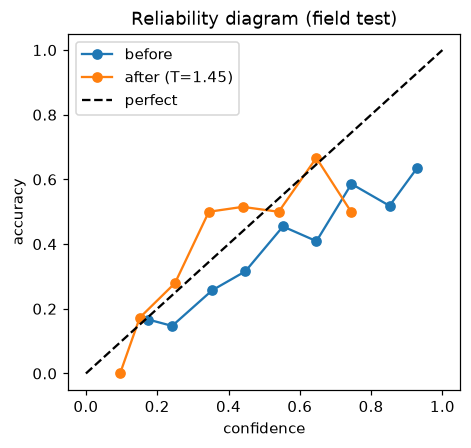

In [9]:
from lab_to_field.models import build_model
from lab_to_field.data import build_transforms, make_loader
model = build_model(best_cfg["model"], N_CLASSES, pretrained=False)
model.load_state_dict(torch.load(CHECKPOINT_DIR / f"{best_name}.pt")); model.cuda()
S = splits()
val_logits, _, val_labels = predict(model, make_loader(S["field_val"], build_transforms("none", train=False), 128))
T = fit_temperature(val_logits, val_labels)
probs_T = softmax(logits, T)
print(f"temperature T = {T:.2f}")
print(f"field ECE before: {expected_calibration_error(probs, labels):.3f}   after: {expected_calibration_error(probs_T, labels):.3f}")
print(f"field accuracy (unchanged): {(probs.argmax(1) == labels).mean():.3f} = {(probs_T.argmax(1) == labels).mean():.3f}")
fig, ax = plt.subplots(figsize=(4.6, 4.2))
for pr, lab in [(probs, "before"), (probs_T, f"after (T={T:.2f})")]:
    rc = reliability_curve(pr, labels); ax.plot(rc[:, 0], rc[:, 1], marker="o", label=lab)
ax.plot([0, 1], [0, 1], "k--", label="perfect"); ax.set_xlabel("confidence"); ax.set_ylabel("accuracy")
ax.set_title("Reliability diagram (field test)"); ax.legend()
fig.savefig(FIGURES_DIR / "05_reliability.png", bbox_inches="tight")

**Read it:** points below the diagonal mean "more confident than accurate". After temperature scaling the curve should move toward the diagonal.

## F. Abstention: answering only when sure
The app can refuse to answer low-confidence photos ("not sure, please ask an expert / take a clearer photo").
The **risk–coverage curve** shows the trade-off: answer fewer photos (lower coverage), get more of them right.

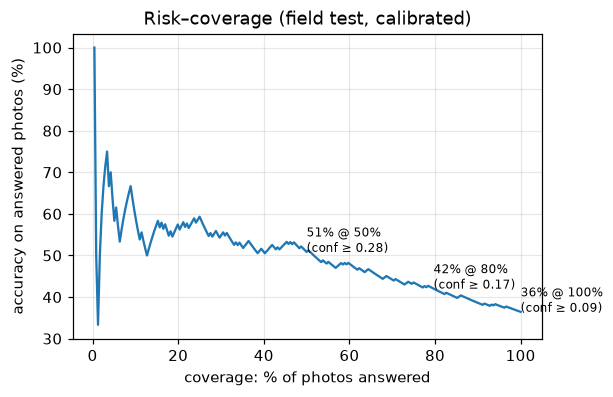

In [10]:
cov, acc, thr = risk_coverage(probs_T, labels)
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(cov * 100, acc * 100); ax.set_xlabel("coverage: % of photos answered"); ax.set_ylabel("accuracy on answered photos (%)")
ax.set_title("Risk–coverage (field test, calibrated)"); ax.grid(alpha=.3)
for c in (1.0, 0.8, 0.5):
    i = int(c * len(cov)) - 1
    ax.annotate(f"{acc[i]:.0%} @ {c:.0%}\n(conf ≥ {thr[i]:.2f})", (cov[i] * 100, acc[i] * 100), fontsize=8)
fig.savefig(FIGURES_DIR / "05_risk_coverage.png", bbox_inches="tight")

## G. The final model for the app
Best augmentation + best optimizer + best loss, trained on the **field track** (lab photos + PlantDoc train photos), since a deployed app should use every real photo we have.
Then temperature calibration on PlantDoc validation. The temperature and an abstain threshold are saved for the app.

In [11]:
final_cfg = TrainConfig(name="05_final_field", model="mobilenetv3_large_100", epochs=8, augment=best_cfg["augment"],
                        optimizer=best_cfg["optimizer"], lr=best_cfg["lr"], loss=best_cfg["loss"])
final = run(final_cfg, track="field")
model = build_model("mobilenetv3_large_100", N_CLASSES, pretrained=False)
model.load_state_dict(torch.load(CHECKPOINT_DIR / "05_final_field.pt")); model.cuda()
vl, _, vy = predict(model, make_loader(S["field_val"], build_transforms("none", train=False), 128))
T_final = fit_temperature(vl, vy)
# Abstain threshold: the lowest confidence at which validation accuracy of answered photos is still >= 80%
c, a, t = risk_coverage(softmax(vl, T_final), vy)
ok = np.where(a >= 0.80)[0]
threshold = float(t[ok[-1]]) if len(ok) else 0.9
d = np.load(RESULTS_DIR / "preds" / "05_final_field__field_test.npz")
pt = softmax(d["logits"], T_final)
answered = pt.max(1) >= threshold
calib = {"temperature": T_final, "abstain_threshold": threshold, "classes": CLASSES}
(RESULTS_DIR / "calibration.json").write_text(json.dumps(calib, indent=2))
print(f"T = {T_final:.2f}, abstain below confidence {threshold:.2f}")
print(f"field test: accuracy {(pt.argmax(1) == d['labels']).mean():.1%} on all photos | "
      f"answers {answered.mean():.0%} of photos with {(pt.argmax(1) == d['labels'])[answered].mean():.1%} accuracy | "
      f"ECE {expected_calibration_error(pt, d['labels']):.3f}")

[05_final_field] loaded saved result (delete 05_final_field.json or pass force=True to retrain): lab acc 0.980 | field val 0.671 | field test 0.644


T = 0.90, abstain below confidence 0.54
field test: accuracy 64.4% on all photos | answers 71% of photos with 77.8% accuracy | ECE 0.108


### Our results
All MobileNetV3 runs use the augmentation chosen in notebook 04 (`bg_field`), lab-only training.

| Experiment | Field val (choose) | Field test | Field ECE |
|---|---|---|---|
| A · AdamW, cross-entropy | 28.9% | 31.4% | 0.44 |
| A · SGD + momentum | 27.7% | 33.5% | 0.37 |
| B · AdamW + **label smoothing** | **29.4%** | 36.4% | **0.16** |
| B · AdamW + focal loss | 24.3% | 29.7% | 0.37 |
| C · scratch CNN ReLU / SiLU / GELU | 7.1 / 9.4 / 8.0% | 8.9 / 10.2 / 10.2% | ~0.67 |

1. **Optimizer:** AdamW and SGD are within noise; AdamW is kept (better on validation, less tuning).
2. **Label smoothing is the win here:** similar accuracy, but calibration error drops from 0.44 to 0.16. The model stops claiming certainty it does not have.
3. **Focal loss does not help:** our training set is already capped at 500 photos per class, so there is little imbalance for it to fix.
4. **Activations barely matter** (~1 point) compared with the data problem (13+ points from background replacement).

**Final model** (field track + bg_field + AdamW + label smoothing):

| | Value |
|---|---|
| Field test accuracy | **64.4%** (95% CI 58–70%) |
| Field ECE | **0.089** before temperature scaling, 0.108 after |
| With abstention (threshold 0.54, set on validation) | answers **71%** of photos with **77.8%** accuracy |

**Honest note on temperature scaling:** label smoothing had already calibrated the model, so the temperature fitted on validation (T = 0.90) slightly *worsened* test ECE. Calibration fitted on ~350 photos is noisy; the lesson is to always check it on held-out data, which we did.
Same field accuracy as the plain field-track model in notebook 03 (64.4%), but far more honest confidence (ECE 0.23 → 0.09).

## Summary and review questions
**Decisions made in this notebook:** optimizer and loss chosen on field *validation* accuracy; the final model is calibrated with temperature scaling; the app abstains below a threshold chosen on validation data, never on the test set.

1. Explain the difference between SGD with momentum, Adam and AdamW.
2. Why do we use learning-rate warm-up and cosine decay?
3. What does label smoothing change in the target? Why can it improve calibration?
4. When is focal loss useful?
5. Why can a dying ReLU happen, and how do SiLU and GELU avoid it?
6. Define precision, recall, F1 and macro-F1. Which one would a farmer care about for a dangerous disease?
7. What is ECE? How does temperature scaling reduce it without changing accuracy?
8. What is a risk–coverage curve, and why is abstaining a feature, not a weakness?